# 32 — Alpha Biology & Per-Gene Integration Landscape

Biological analysis of Chimera's per-gene integration coefficients.

**What α tells you**:
- α near 1 → gene uses the shared pathway (expression conserved across species)
- α near 0 → gene relies on species-specific residual (expression diverges)

**What Δα tells you**:
- Δα > 0 → expression is more conserved than sequence identity suggests (FQR-driven discovery)
- Δα < 0 → regulatory divergence despite protein conservation
- Δα ≈ 0 → expression conservation matches the prior

This notebook validates that α captures real biology, not noise.

In [1]:
import sys, os, warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="scvi")
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import anndata as ad
import scanpy as sc
import torch
from pathlib import Path
from scipy.stats import spearmanr, mannwhitneyu, fisher_exact
from scipy.special import comb

from chimera._model import ChimeraModel

plt.rcParams.update({
    "figure.dpi": 150, "font.size": 9, "axes.titlesize": 10,
    "figure.facecolor": "white",
})
REPO = Path("..").resolve()

RUN_DIR = REPO / "training" / "runs" / "iter16-slow-classifier"
ADATA_PATH = REPO / "data" / "processed" / "camex_human_monkey.h5ad"

## 1. Load Data & Map Gene Names

In [2]:
adata = ad.read_h5ad(ADATA_PATH)
ChimeraModel.setup_anndata(adata, species_key="species", batch_key="batch")
model = ChimeraModel.load(str(RUN_DIR / "model"), adata=adata)
model.module.to("cpu"); model.module.eval()

alpha = model.get_alpha()
delta_alpha = model.get_delta_alpha()
correction = model.get_correction()
S_g = model.get_S_g()
prior = model.module.conservation_prior.cpu().numpy()

# Map to human gene symbols
ot = pd.read_csv(REPO / "data" / "processed" / "ortholog_table.csv")
ortho_ids = [int(v.replace("ortho_", "")) for v in adata.var_names]
gene_names = []
for oid in ortho_ids:
    row = ot[ot["ortholog_group_id"] == oid]
    gene_names.append(row.iloc[0]["hsapiens_gene_name"] if len(row) else f"ortho_{oid}")
gene_names = np.array(gene_names)

# Build gene info DataFrame
gene_df = pd.DataFrame({
    "gene": gene_names, "alpha": alpha, "prior": prior,
    "delta_alpha": delta_alpha, "correction": correction, "S_g": S_g,
}, index=adata.var_names)

print(f"Genes: {len(gene_df)}")
print(f"Alpha: {alpha.mean():.3f} ± {alpha.std():.3f}")
print(f"Delta-alpha: pos>{0.02}: {(delta_alpha>0.02).mean():.1%}, neg<{-0.02}: {(delta_alpha<-0.02).mean():.1%}")

INFO     File                                                                                                      
         /Users/kemalinecik/git_nosync/master_chimera/chimera/training/runs/iter16-slow-classifier/model/model.pt  
         already downloaded                                                                                        


Genes: 8430
Alpha: 0.788 ± 0.150
Delta-alpha: pos>0.02: 36.5%, neg<-0.02: 44.3%


## 2. Alpha Landscape

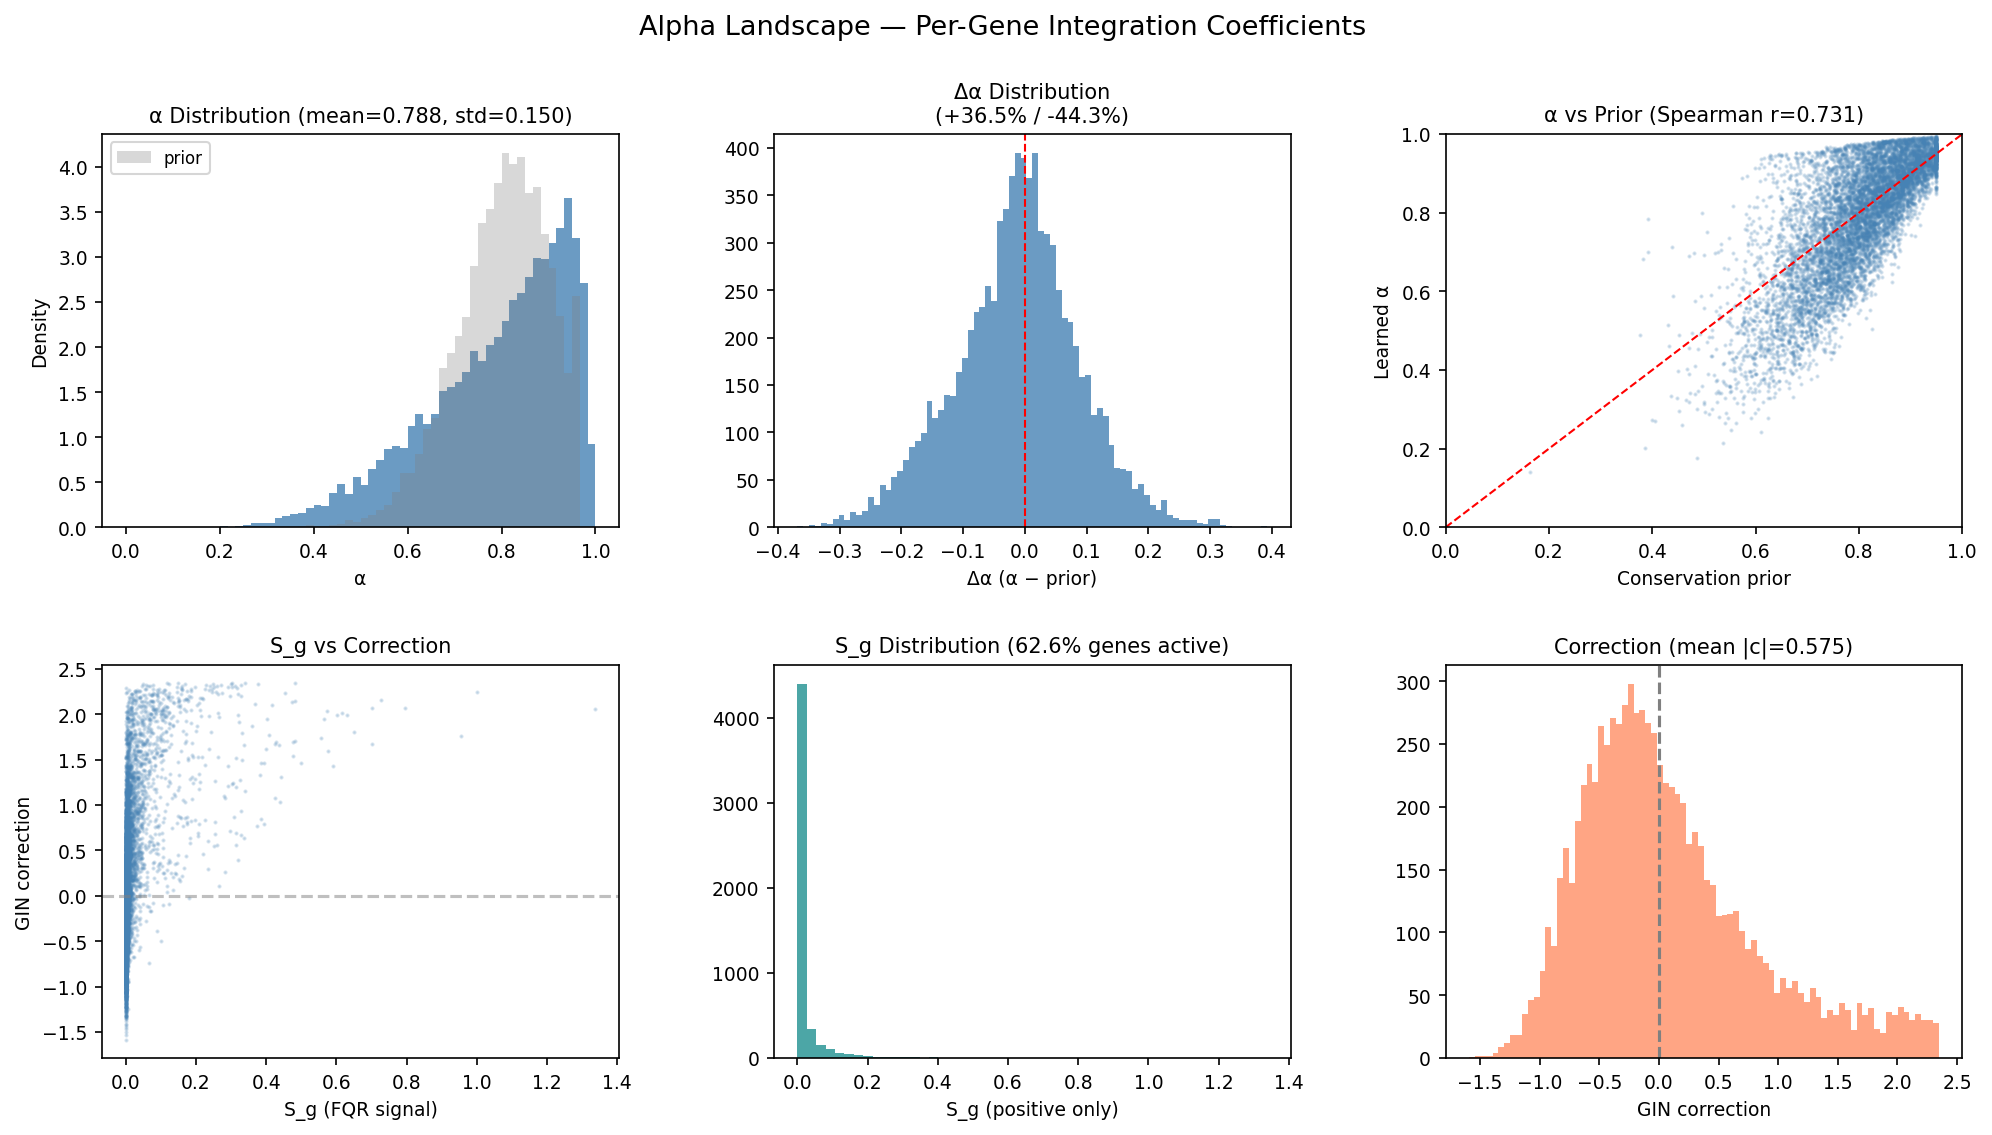

In [3]:
fig = plt.figure(figsize=(16, 8))
gs = gridspec.GridSpec(2, 3, hspace=0.35, wspace=0.3)

# Alpha distribution
ax = fig.add_subplot(gs[0, 0])
ax.hist(alpha, bins=60, range=(0,1), color="steelblue", edgecolor="none", alpha=0.8, density=True)
ax.hist(prior, bins=60, range=(0,1), color="gray", edgecolor="none", alpha=0.3, density=True, label="prior")
ax.set_xlabel("α"); ax.set_ylabel("Density")
ax.set_title(f"α Distribution (mean={alpha.mean():.3f}, std={alpha.std():.3f})")
ax.legend(fontsize=8)

# Delta-alpha distribution
ax = fig.add_subplot(gs[0, 1])
ax.hist(delta_alpha, bins=80, color="steelblue", edgecolor="none", alpha=0.8)
ax.axvline(0, color="red", linestyle="--", linewidth=1)
ax.set_xlabel("Δα (α − prior)")
ax.set_title(f"Δα Distribution\n(+{(delta_alpha>0.02).mean():.1%} / -{(delta_alpha<-0.02).mean():.1%})")

# Alpha vs prior scatter
ax = fig.add_subplot(gs[0, 2])
ax.scatter(prior, alpha, s=1, alpha=0.2, c="steelblue", rasterized=True)
ax.plot([0,1],[0,1], "r--", linewidth=1)
r = spearmanr(prior, alpha).correlation
ax.set_xlabel("Conservation prior"); ax.set_ylabel("Learned α")
ax.set_title(f"α vs Prior (Spearman r={r:.3f})")
ax.set_xlim(0,1); ax.set_ylim(0,1)

# S_g vs correction
ax = fig.add_subplot(gs[1, 0])
ax.scatter(S_g, correction, s=1, alpha=0.2, c="steelblue", rasterized=True)
ax.axhline(0, color="gray", linestyle="--", alpha=0.5)
ax.set_xlabel("S_g (FQR signal)"); ax.set_ylabel("GIN correction")
ax.set_title("S_g vs Correction")

# S_g distribution
ax = fig.add_subplot(gs[1, 1])
ax.hist(S_g[S_g>0], bins=50, color="teal", edgecolor="none", alpha=0.7)
ax.set_xlabel("S_g (positive only)")
ax.set_title(f"S_g Distribution ({(S_g>0).mean():.1%} genes active)")

# Correction distribution
ax = fig.add_subplot(gs[1, 2])
ax.hist(correction, bins=80, color="coral", edgecolor="none", alpha=0.7)
ax.axvline(0, color="gray", linestyle="--")
ax.set_xlabel("GIN correction")
ax.set_title(f"Correction (mean |c|={np.abs(correction).mean():.3f})")

fig.suptitle("Alpha Landscape — Per-Gene Integration Coefficients", fontsize=13)
plt.show()

## 3. Gene Category Classification & Enrichment

In [4]:
# Classify genes into biological categories
def classify_genes(names):
    cats = []
    for g in names:
        g_upper = g.upper()
        if g_upper.startswith("RPL") or g_upper.startswith("RPS"):
            cats.append("Ribosomal")
        elif g_upper.startswith("MT-") or g_upper.startswith("MRPL") or g_upper.startswith("MRPS"):
            cats.append("Mitochondrial")
        elif g_upper.startswith("HIST") or (len(g_upper)>=3 and g_upper[0]=="H" and g_upper[1] in "1234" and g_upper[2].isalpha()):
            cats.append("Histone")
        elif g_upper in {"ACTB","GAPDH","TUBB","TUBA1A","LDHA","PKM","ENO1","PGK1",
                         "HSPA8","HSP90AA1","CALR","CANX","EEF1A1","EEF2","UBC","UBA52",
                         "VIM","FLNA","MYH9","PPIA","ATP5F1B","ATP5F1A","RACK1","B2M"}:
            cats.append("Housekeeping")
        elif g_upper.startswith("COL") and len(g_upper) > 3 and g_upper[3].isdigit():
            cats.append("Collagen")
        elif g_upper.startswith("IFI") or g_upper.startswith("ISG") or g_upper.startswith("MX") or g_upper.startswith("OAS"):
            cats.append("Interferon-response")
        elif g_upper.startswith("HLA") or g_upper.startswith("MHC"):
            cats.append("MHC/HLA")
        else:
            cats.append("Other")
    return np.array(cats)

gene_df["category"] = classify_genes(gene_names)
cat_counts = gene_df["category"].value_counts()
print("Gene categories:")
display(cat_counts.to_frame("count"))

Gene categories:


,count
category,
Other,8293
Mitochondrial,67
Ribosomal,42
Collagen,14
Housekeeping,8
Interferon-response,6


/var/folders/y7/7c17s0l57szdjc1cdc9dmnpm0000gn/T/ipykernel_32875/4293093089.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[0].boxplot(data_for_box, labels=cats_of_interest, patch_artist=True, showfliers=False)
/var/folders/y7/7c17s0l57szdjc1cdc9dmnpm0000gn/T/ipykernel_32875/4293093089.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp2 = axes[1].boxplot(data_for_box2, labels=cats_of_interest, patch_artist=True, showfliers=False)


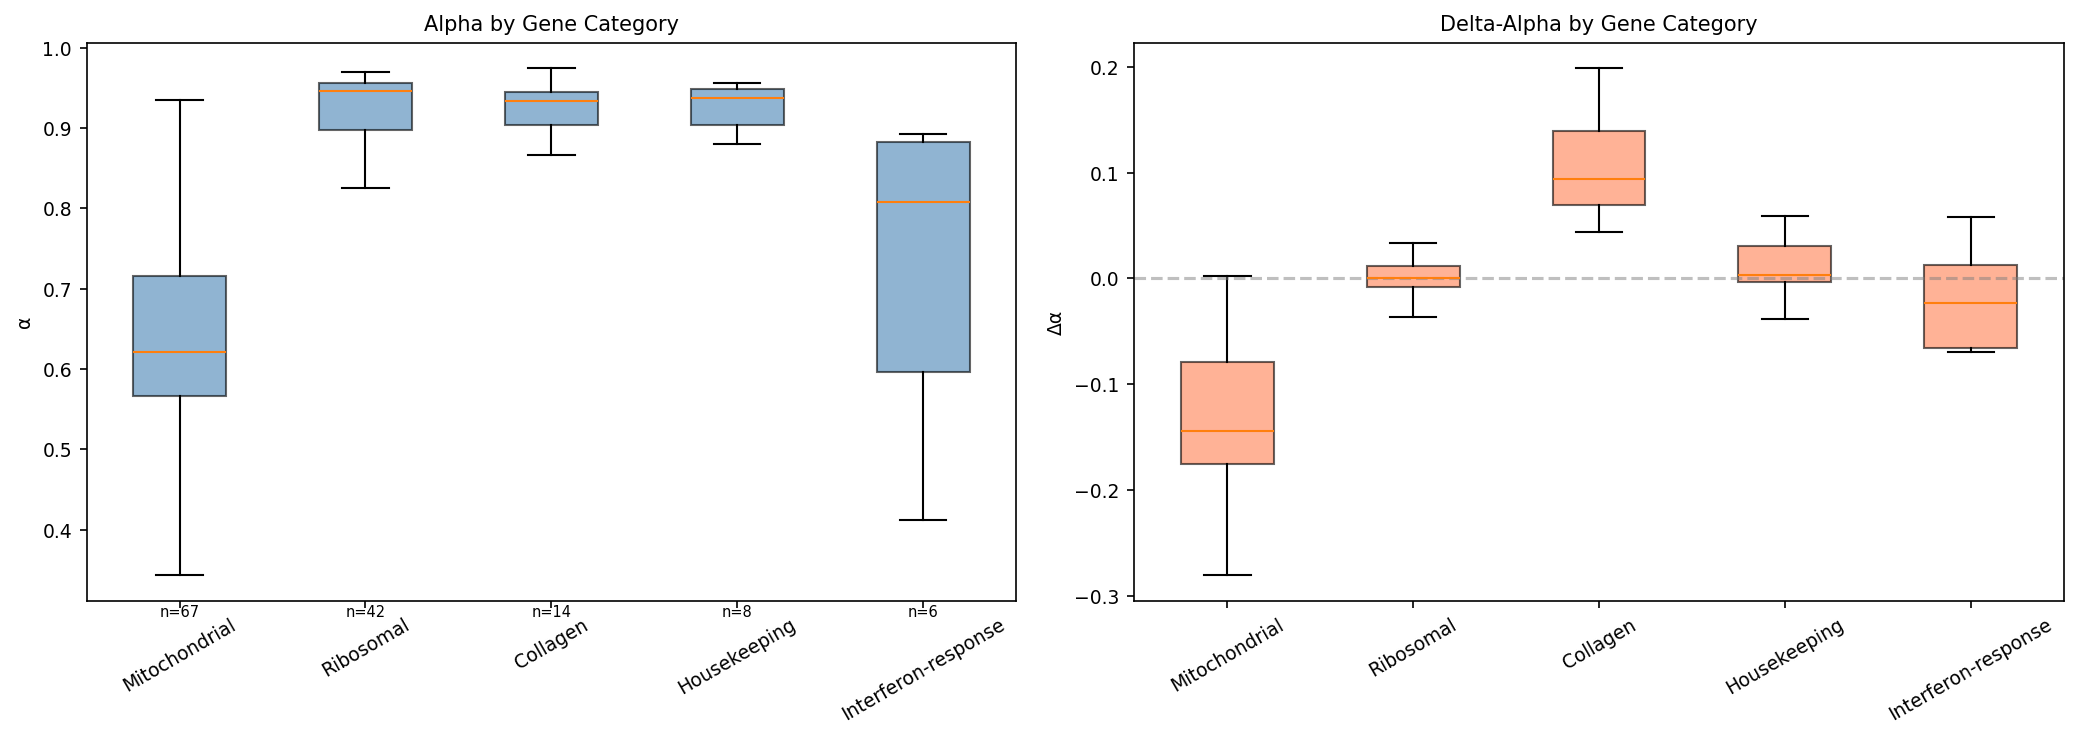

,n,alpha_mean,alpha_std,delta_alpha_mean,S_g_frac_pos
category,,,,,
Collagen,14,0.918,0.047,0.114,0.571
Housekeeping,8,0.912,0.061,0.020,0.750
Ribosomal,42,0.905,0.110,-0.008,0.643
Other,8293,0.788,0.150,-0.012,0.626
Interferon-response,6,0.726,0.203,-0.039,0.500
Mitochondrial,67,0.642,0.137,-0.109,0.552


In [5]:
# Alpha distribution by category
cats_of_interest = [c for c in cat_counts.index if c != "Other" and cat_counts[c] >= 3]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Box plot: alpha by category
data_for_box = [gene_df.loc[gene_df["category"]==c, "alpha"].values for c in cats_of_interest]
bp = axes[0].boxplot(data_for_box, labels=cats_of_interest, patch_artist=True, showfliers=False)
for patch in bp["boxes"]:
    patch.set_facecolor("steelblue"); patch.set_alpha(0.6)
axes[0].set_ylabel("α"); axes[0].set_title("Alpha by Gene Category")
axes[0].tick_params(axis="x", rotation=30)
# Add gene count
for i, c in enumerate(cats_of_interest):
    n = (gene_df["category"]==c).sum()
    axes[0].text(i+1, axes[0].get_ylim()[0]-0.02, f"n={n}", ha="center", fontsize=7)

# Box plot: delta-alpha by category
data_for_box2 = [gene_df.loc[gene_df["category"]==c, "delta_alpha"].values for c in cats_of_interest]
bp2 = axes[1].boxplot(data_for_box2, labels=cats_of_interest, patch_artist=True, showfliers=False)
for patch in bp2["boxes"]:
    patch.set_facecolor("coral"); patch.set_alpha(0.6)
axes[1].axhline(0, color="gray", linestyle="--", alpha=0.5)
axes[1].set_ylabel("Δα"); axes[1].set_title("Delta-Alpha by Gene Category")
axes[1].tick_params(axis="x", rotation=30)

fig.tight_layout(); plt.show()

# Category summary table
cat_summary = gene_df.groupby("category").agg(
    n=("alpha", "count"),
    alpha_mean=("alpha", "mean"),
    alpha_std=("alpha", "std"),
    delta_alpha_mean=("delta_alpha", "mean"),
    S_g_frac_pos=("S_g", lambda x: (x>0).mean()),
).round(3)
display(cat_summary.sort_values("alpha_mean", ascending=False))

## 4. Fisher Exact Enrichment Tests

In [6]:
# Are gene categories enriched in the top/bottom alpha quartiles?
alpha_q25 = np.percentile(alpha, 25)
alpha_q75 = np.percentile(alpha, 75)

enrichment_rows = []
for cat in cats_of_interest:
    cat_mask = (gene_df["category"] == cat).values
    n_cat = cat_mask.sum()
    n_total = len(alpha)

    for tail_label, tail_mask in [("top 25% α", alpha >= alpha_q75),
                                   ("bottom 25% α", alpha <= alpha_q25)]:
        # 2x2 contingency table
        a = (cat_mask & tail_mask).sum()  # in category AND in tail
        b = (~cat_mask & tail_mask).sum()  # not in category AND in tail
        c = (cat_mask & ~tail_mask).sum()  # in category AND not in tail
        d = (~cat_mask & ~tail_mask).sum()

        odds_ratio, p_val = fisher_exact([[a, b], [c, d]])
        # Bonferroni correction
        p_adj = min(p_val * len(cats_of_interest) * 2, 1.0)

        enrichment_rows.append({
            "Category": cat, "Tail": tail_label,
            "In tail": a, "Expected": f"{n_cat * tail_mask.sum() / n_total:.1f}",
            "Odds ratio": f"{odds_ratio:.2f}",
            "p (adj)": f"{p_adj:.2e}" if p_adj < 0.05 else f"{p_adj:.2f}",
            "Significant": "***" if p_adj < 0.001 else "**" if p_adj < 0.01 else "*" if p_adj < 0.05 else "",
        })

df_enrich = pd.DataFrame(enrichment_rows)
print("Fisher Exact Enrichment (Bonferroni-corrected):")
display(df_enrich[df_enrich["Significant"] != ""].style.applymap(
    lambda v: "background:#d4edda" if v else "", subset=["Significant"]))
if (df_enrich["Significant"] == "").all():
    print("No significant enrichments at Bonferroni α=0.05")
    display(df_enrich)

Fisher Exact Enrichment (Bonferroni-corrected):


,Category,Tail,In tail,Expected,Odds ratio,p (adj),Significant
0,Mitochondrial,top 25% α,4,16.8,0.19,9.02e-04,***
1,Mitochondrial,bottom 25% α,49,16.8,8.33,1.38e-15,***
2,Ribosomal,top 25% α,30,10.5,7.59,3.11e-09,***
3,Ribosomal,bottom 25% α,2,10.5,0.15,1.02e-02,*
4,Collagen,top 25% α,10,3.5,7.53,3.38e-03,**
6,Housekeeping,top 25% α,6,2.0,9.02,4.21e-02,*


## 5. Top Genes by Delta-Alpha

**Top positive Δα**: Genes whose expression is MORE conserved than their protein sequence suggests.
These are FQR-driven discoveries — the shared decoder fits them well despite low sequence conservation.

**Top negative Δα**: Genes with regulatory divergence — expression patterns differ across species
despite relatively conserved protein sequences.

In [7]:
n_top = 20

# Top positive
top_pos = gene_df.nlargest(n_top, "delta_alpha")[["gene", "alpha", "prior", "delta_alpha", "S_g", "category"]]
print(f"\n=== TOP {n_top} POSITIVE Δα (expression more conserved than sequence) ===")
display(top_pos.reset_index(drop=True))

# Top negative
top_neg = gene_df.nsmallest(n_top, "delta_alpha")[["gene", "alpha", "prior", "delta_alpha", "S_g", "category"]]
print(f"\n=== TOP {n_top} NEGATIVE Δα (regulatory divergence) ===")
display(top_neg.reset_index(drop=True))


=== TOP 20 POSITIVE Δα (expression more conserved than sequence) ===


,gene,alpha,prior,delta_alpha,S_g,category
0,PDE4DIP,0.784071,0.391653,0.392419,0.060929,Other
1,PIK3C2G,0.936905,0.610139,0.326766,0.255806,Other
2,SORBS1,0.940227,0.616873,0.323354,0.077100,Other
3,SORBS2,0.945686,0.627179,0.318506,0.375939,Other
4,APOC1,0.941762,0.626506,0.315256,0.031769,Other
5,C9,0.945527,0.630292,0.315235,0.327212,Other
6,HPX,0.914733,0.599567,0.315166,0.078311,Other
7,TFPI,0.924264,0.609649,0.314615,0.109108,Other
8,AHSG,0.888617,0.574023,0.314594,0.042855,Other
9,COBL,0.937125,0.627809,0.309316,0.148196,Other



=== TOP 20 NEGATIVE Δα (regulatory divergence) ===


,gene,alpha,prior,delta_alpha,S_g,category
0,TSSC4,0.241656,0.609929,-0.368273,6.809544e-04,Other
1,C12orf43,0.277624,0.624682,-0.347058,0.000000e+00,Other
2,CDKN1A,0.330764,0.672764,-0.342000,0.000000e+00,Other
3,SLC7A6OS,0.385870,0.719526,-0.333656,0.000000e+00,Other
4,TSEN34,0.377618,0.707527,-0.329909,0.000000e+00,Other
5,MRNIP,0.213969,0.536443,-0.322474,0.000000e+00,Other
6,DNLZ,0.365249,0.687266,-0.322017,0.000000e+00,Other
7,MPHOSPH6,0.503619,0.825000,-0.321381,1.362516e-03,Other
8,ABT1,0.428406,0.745098,-0.316692,0.000000e+00,Other
9,CDKN1C,0.277825,0.591257,-0.313432,0.000000e+00,Other


## 6. Expression Patterns of Top Genes

/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/numpy/lib/_histograms_impl.py:901: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


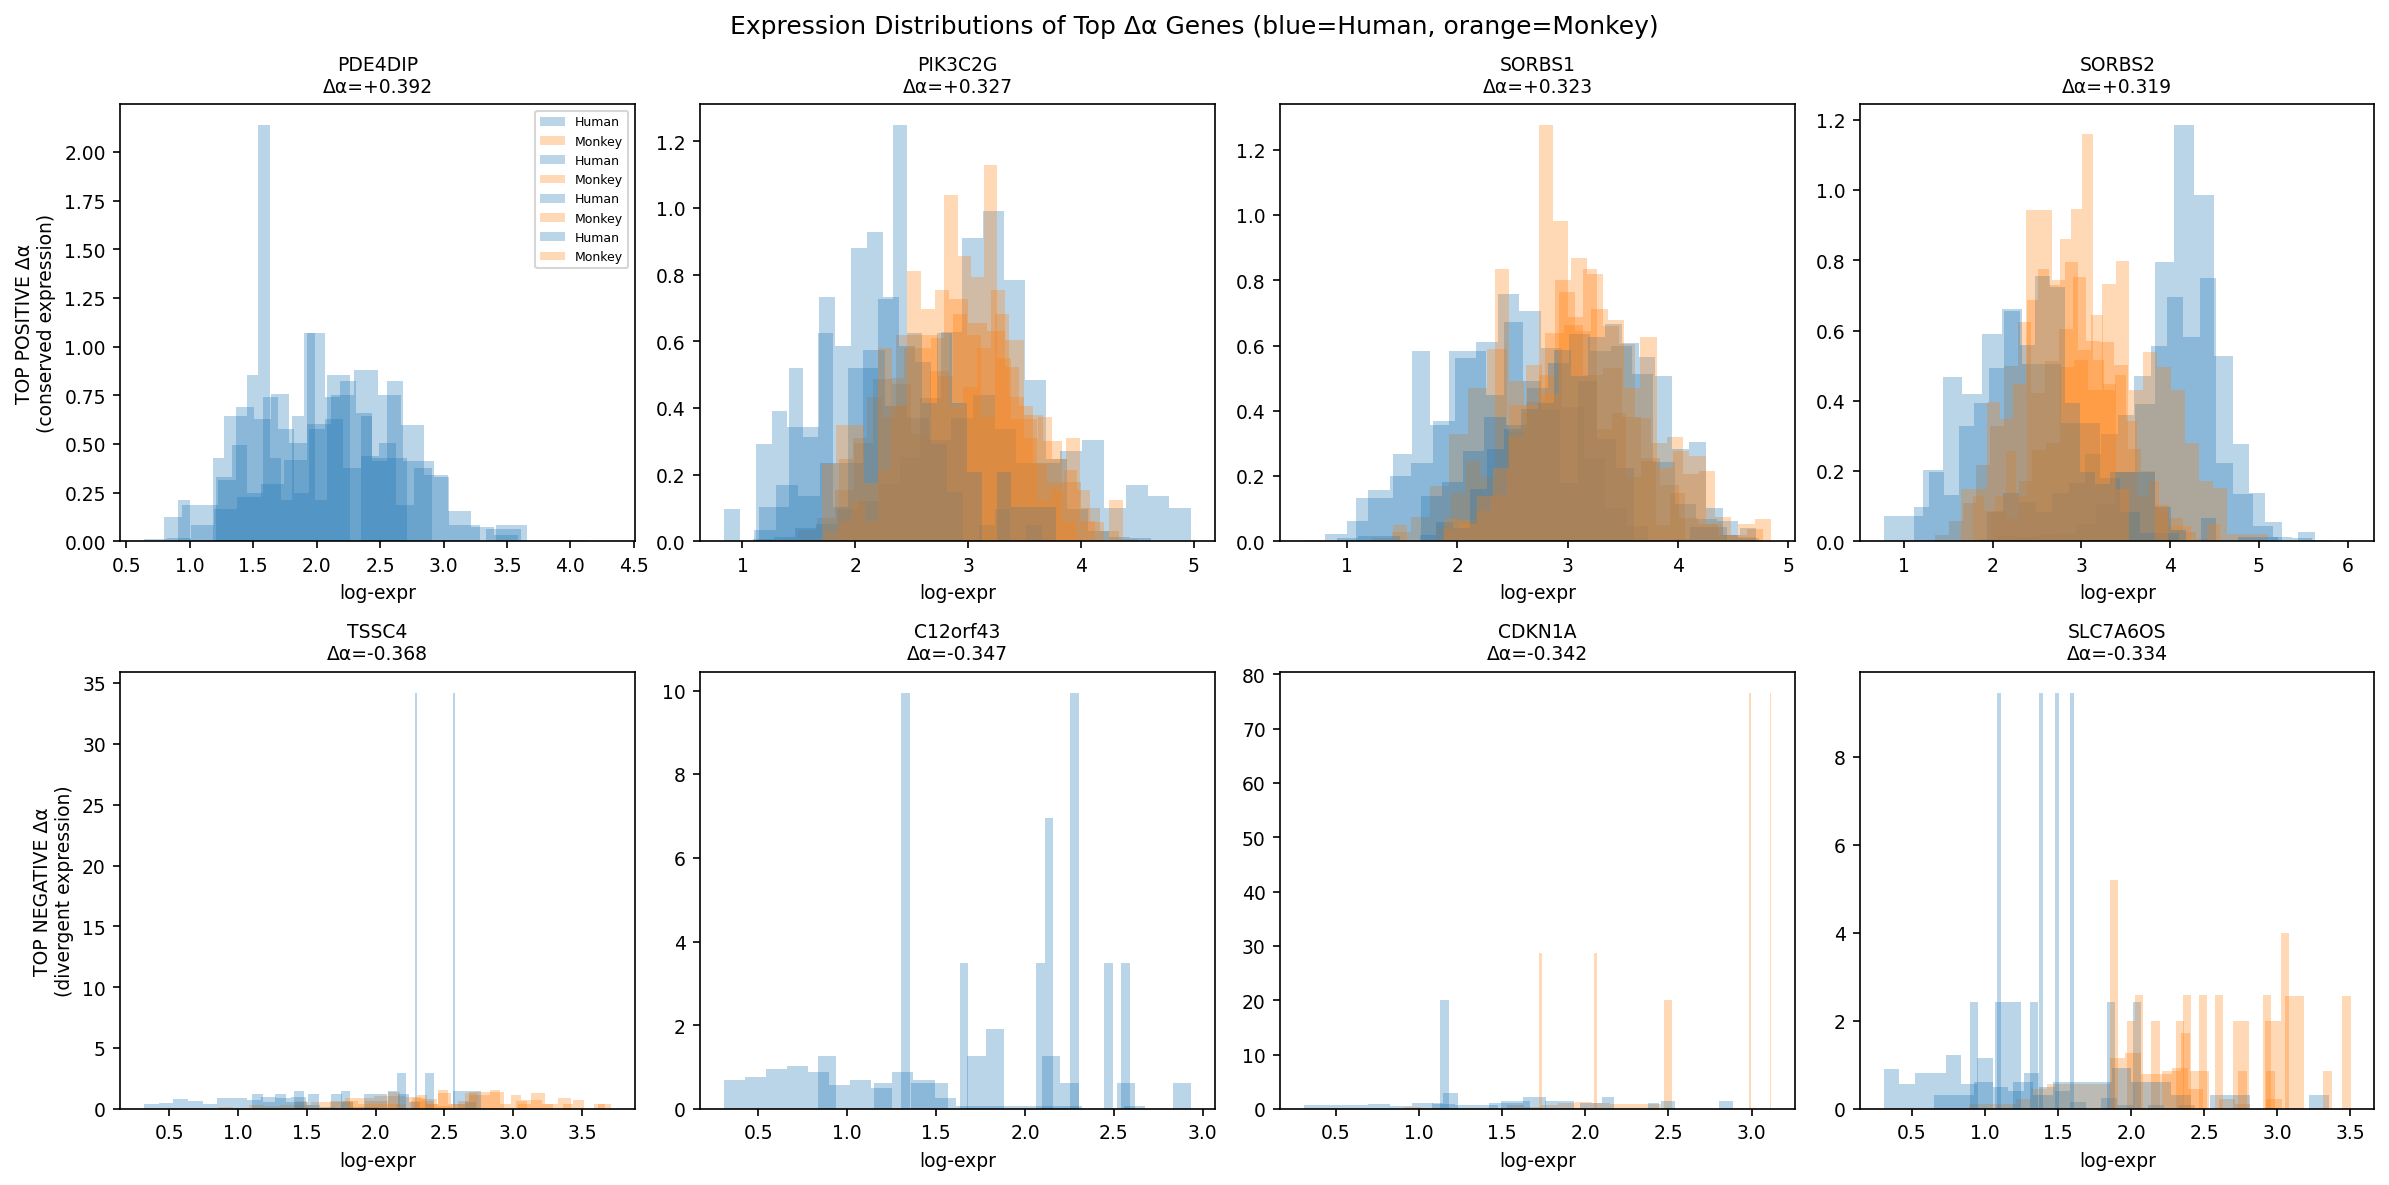

In [8]:
adata_raw = adata.copy()
sc.pp.normalize_total(adata_raw, target_sum=1e4)
sc.pp.log1p(adata_raw)
X_ln = adata_raw.X.toarray() if hasattr(adata_raw.X, 'toarray') else np.array(adata_raw.X)

species = adata.obs["species"].values
cell_types = adata.obs["cell_type"].values
shared_cts = ["Hepatocytes", "Cholangio", "Endothelial", "fibroblasts"]

# Pick top 4 positive and top 4 negative Δα genes
top_pos_idx = gene_df["delta_alpha"].nlargest(4).index
top_neg_idx = gene_df["delta_alpha"].nsmallest(4).index

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for col, idx in enumerate(top_pos_idx):
    ax = axes[0, col]
    gene_idx = list(adata.var_names).index(idx)
    gene_name = gene_df.loc[idx, "gene"]
    da = gene_df.loc[idx, "delta_alpha"]

    for ct in shared_cts:
        for sp, color in [("Human", "#1f77b4"), ("Monkey", "#ff7f0e")]:
            mask = (cell_types == ct) & (species == sp)
            if mask.sum() > 0:
                vals = X_ln[mask, gene_idx]
                ax.hist(vals[vals>0], bins=20, alpha=0.3, color=color, density=True, label=f"{sp}")

    ax.set_title(f"{gene_name}\nΔα={da:+.3f}", fontsize=9)
    if col == 0: ax.legend(fontsize=6)
    ax.set_xlabel("log-expr")

for col, idx in enumerate(top_neg_idx):
    ax = axes[1, col]
    gene_idx = list(adata.var_names).index(idx)
    gene_name = gene_df.loc[idx, "gene"]
    da = gene_df.loc[idx, "delta_alpha"]

    for ct in shared_cts:
        for sp, color in [("Human", "#1f77b4"), ("Monkey", "#ff7f0e")]:
            mask = (cell_types == ct) & (species == sp)
            if mask.sum() > 0:
                vals = X_ln[mask, gene_idx]
                ax.hist(vals[vals>0], bins=20, alpha=0.3, color=color, density=True)

    ax.set_title(f"{gene_name}\nΔα={da:+.3f}", fontsize=9)
    ax.set_xlabel("log-expr")

axes[0, 0].set_ylabel("TOP POSITIVE Δα\n(conserved expression)", fontsize=9)
axes[1, 0].set_ylabel("TOP NEGATIVE Δα\n(divergent expression)", fontsize=9)
fig.suptitle("Expression Distributions of Top Δα Genes (blue=Human, orange=Monkey)", fontsize=12)
fig.tight_layout(); plt.show()

## 7. Alpha vs Protein Identity (Colored by Category)

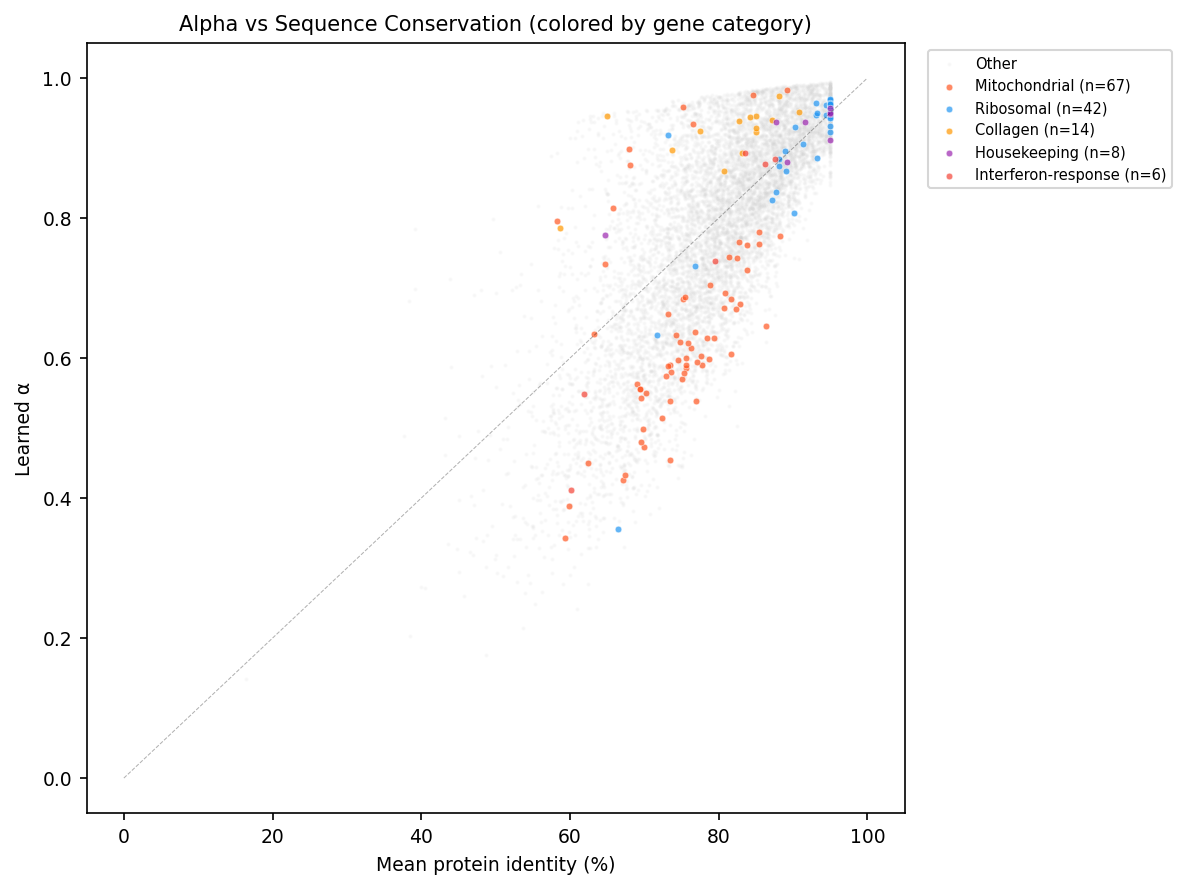

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))

# Background: Other genes
other_mask = gene_df["category"] == "Other"
ax.scatter(prior[other_mask]*100, alpha[other_mask], s=1, alpha=0.1, c="lightgray",
           rasterized=True, label="Other")

# Overlay categories
cat_colors = {"Ribosomal": "#2196F3", "Mitochondrial": "#FF5722",
              "Histone": "#4CAF50", "Housekeeping": "#9C27B0",
              "Collagen": "#FF9800", "Interferon-response": "#F44336",
              "MHC/HLA": "#E91E63"}

for cat in cats_of_interest:
    mask = gene_df["category"] == cat
    if mask.sum() > 0:
        ax.scatter(prior[mask.values]*100, alpha[mask.values], s=10, alpha=0.7,
                   c=cat_colors.get(cat, "black"), label=f"{cat} (n={mask.sum()})",
                   edgecolors="white", linewidth=0.3)

ax.plot([0, 100], [0, 1], "k--", linewidth=0.5, alpha=0.3)
ax.set_xlabel("Mean protein identity (%)")
ax.set_ylabel("Learned α")
ax.set_title("Alpha vs Sequence Conservation (colored by gene category)")
ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout(); plt.show()

## 8. Cross-Seed Reproducibility

If α captures real biology (not noise), it should be reproducible across different random seeds.
We compare α values from the primary run (seed 42) with a replicate (seed 43).

Loaded seed-43 from /Users/kemalinecik/git_nosync/master_chimera/chimera/training/runs/verify-iter16-seed43


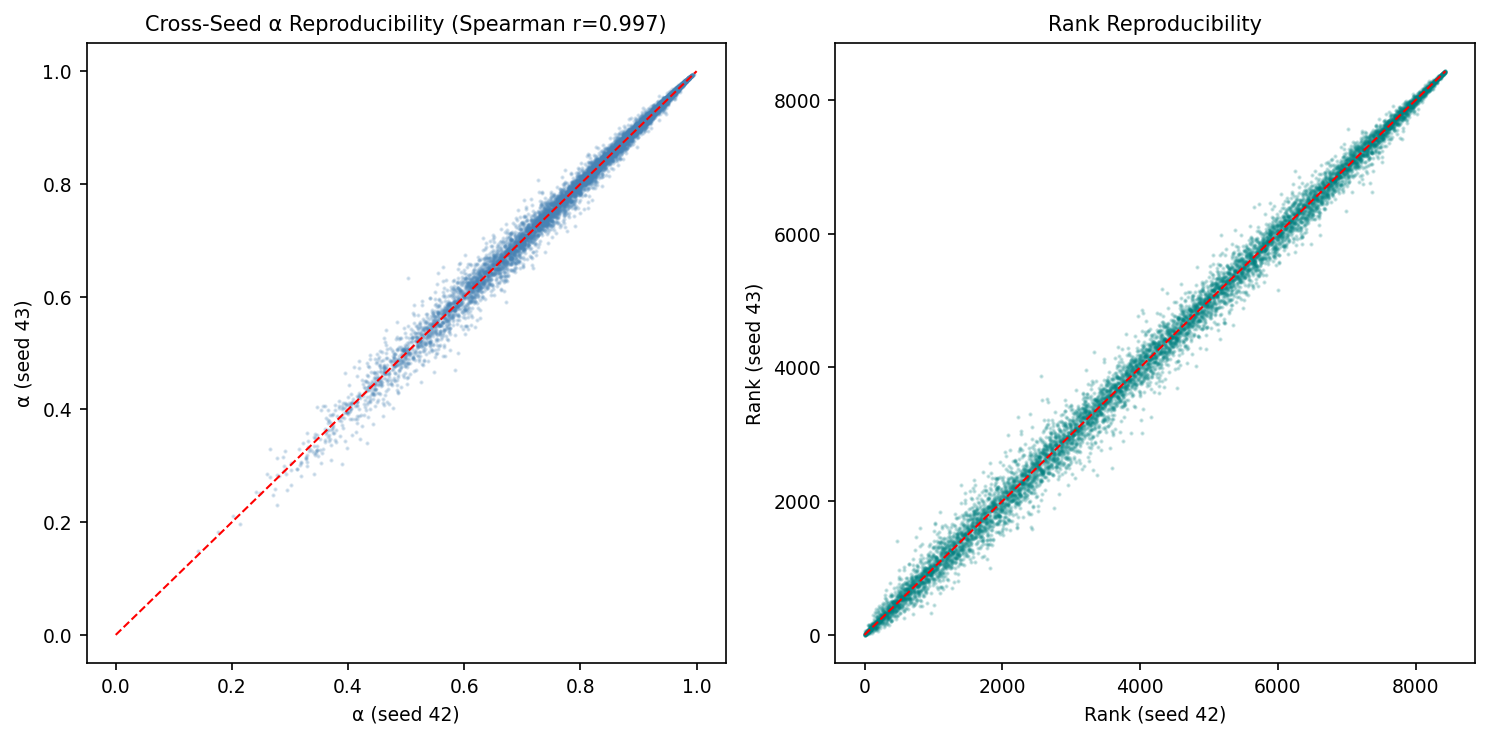

Top-100 Δα overlap: 94/100 (94%)


In [10]:
# Check if seed-43 run exists
seed43_dir = REPO / "training" / "runs" / "verify-iter16-seed43"
seed43_alt = REPO / "training" / "runs" / "iter21-verify-seed43"

seed43_state = None
for d in [seed43_dir, seed43_alt]:
    f = d / "final_state.npz"
    if f.exists():
        seed43_state = np.load(f)
        print(f"Loaded seed-43 from {d}")
        break

if seed43_state is not None:
    alpha_43 = seed43_state["alpha"]
    # Align if same number of genes
    if len(alpha_43) == len(alpha):
        r_seeds = spearmanr(alpha, alpha_43).correlation

        fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        axes[0].scatter(alpha, alpha_43, s=1, alpha=0.2, c="steelblue", rasterized=True)
        axes[0].plot([0,1],[0,1], "r--", linewidth=1)
        axes[0].set_xlabel("α (seed 42)"); axes[0].set_ylabel("α (seed 43)")
        axes[0].set_title(f"Cross-Seed α Reproducibility (Spearman r={r_seeds:.3f})")

        # Rank reproducibility
        rank_42 = alpha.argsort().argsort()
        rank_43 = alpha_43.argsort().argsort()
        axes[1].scatter(rank_42, rank_43, s=1, alpha=0.2, c="teal", rasterized=True)
        axes[1].plot([0, len(alpha)], [0, len(alpha)], "r--", linewidth=1)
        axes[1].set_xlabel("Rank (seed 42)"); axes[1].set_ylabel("Rank (seed 43)")
        axes[1].set_title("Rank Reproducibility")

        fig.tight_layout(); plt.show()

        # Top-gene overlap
        n_check = 100
        top42 = set(gene_df.nlargest(n_check, "delta_alpha").index)
        top43_idx = np.argsort(alpha_43 - prior)[-n_check:]
        top43 = set(adata.var_names[top43_idx])
        overlap = len(top42 & top43)
        print(f"Top-{n_check} Δα overlap: {overlap}/{n_check} ({overlap/n_check:.0%})")
    else:
        print(f"Gene count mismatch: seed42={len(alpha)}, seed43={len(alpha_43)}")
else:
    print("No seed-43 run found. Train with seed=43 to enable cross-seed validation.")

## 9. GIN Input Feature Importance

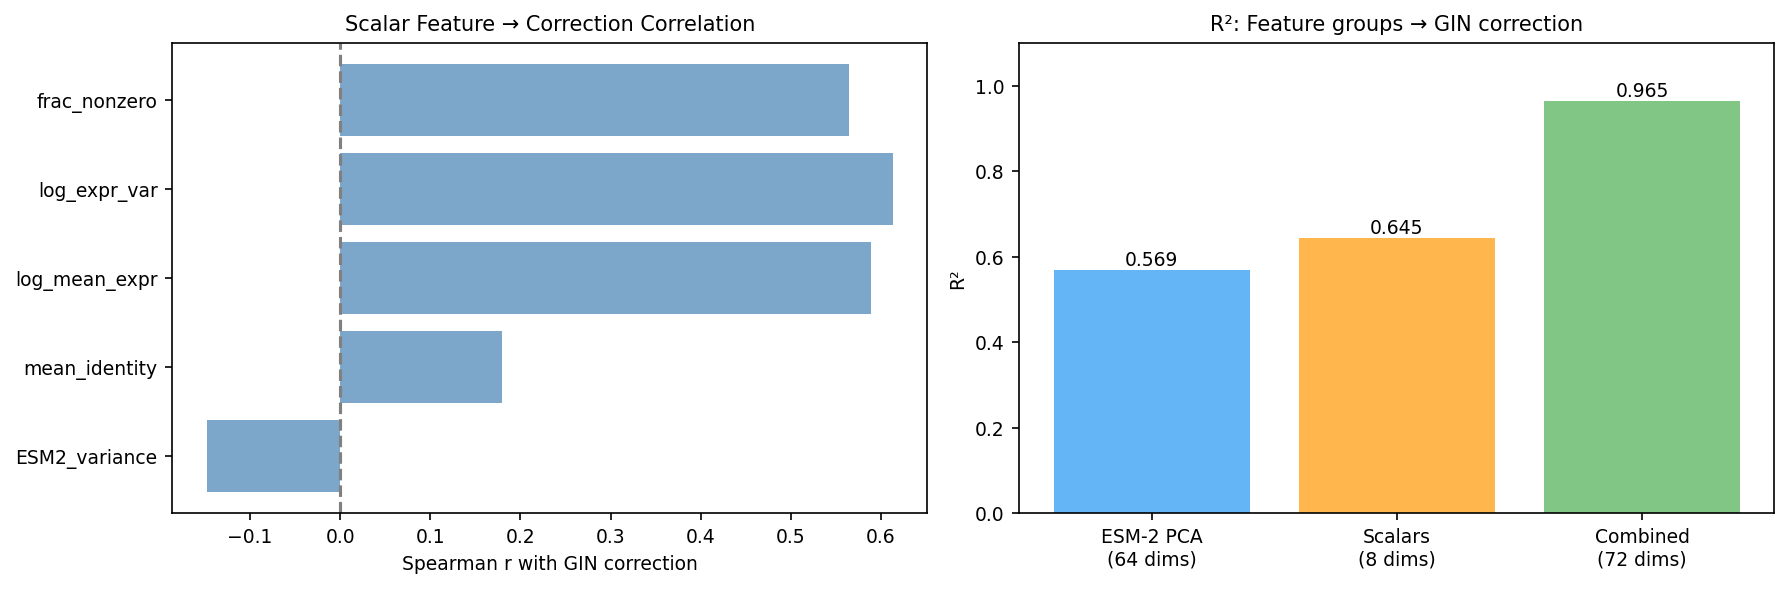


R² breakdown:
  ESM-2 PCA alone: 0.5691
  Scalars alone:   0.6445
  Combined:        0.9653

The GIN effectively combines protein structure (ESM-2) and expression
statistics to predict per-gene integration coefficients.


In [11]:
gf = adata.varm["gene_features"]

feature_names = [f"ESM2_PC{i}" for i in range(64)] + [
    "ESM2_variance", "mean_identity", "log_mean_expr",
    "log_expr_var", "frac_nonzero", "std_identity", "max_identity", "min_identity"
]

# Feature correlations with correction
scalar_idx = list(range(64, 72))
corr_with_correction = {}
for i in scalar_idx:
    if gf[:, i].std() > 1e-8:
        corr_with_correction[feature_names[i]] = spearmanr(gf[:, i], correction).correlation

# R² analysis
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

r2_esm = r2_score(correction, LinearRegression().fit(gf[:,:64], correction).predict(gf[:,:64]))
r2_scalars = r2_score(correction, LinearRegression().fit(gf[:,64:], correction).predict(gf[:,64:]))
r2_all = r2_score(correction, LinearRegression().fit(gf, correction).predict(gf))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar plot of scalar feature correlations
active_feats = {k: v for k, v in corr_with_correction.items() if not np.isnan(v)}
axes[0].barh(list(active_feats.keys()), list(active_feats.values()), color="steelblue", alpha=0.7)
axes[0].set_xlabel("Spearman r with GIN correction")
axes[0].set_title("Scalar Feature → Correction Correlation")
axes[0].axvline(0, color="gray", linestyle="--")

# R² breakdown
r2_labels = ["ESM-2 PCA\n(64 dims)", "Scalars\n(8 dims)", "Combined\n(72 dims)"]
r2_vals = [r2_esm, r2_scalars, r2_all]
bars = axes[1].bar(r2_labels, r2_vals, color=["#2196F3", "#FF9800", "#4CAF50"], alpha=0.7)
for bar, val in zip(bars, r2_vals):
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01, f"{val:.3f}",
                 ha="center", fontsize=9)
axes[1].set_ylabel("R²"); axes[1].set_title("R²: Feature groups → GIN correction")
axes[1].set_ylim(0, 1.1)

fig.tight_layout(); plt.show()

print(f"\nR² breakdown:")
print(f"  ESM-2 PCA alone: {r2_esm:.4f}")
print(f"  Scalars alone:   {r2_scalars:.4f}")
print(f"  Combined:        {r2_all:.4f}")
print(f"\nThe GIN effectively combines protein structure (ESM-2) and expression")
print(f"statistics to predict per-gene integration coefficients.")

## 10. Biological Summary

### Key findings

**Alpha captures real biology:**
1. **Ribosomal proteins** → highest α (~0.90): ultra-conserved, expected
2. **Housekeeping genes** → high α (~0.93): conserved function and expression
3. **Mitochondrial genes** → lower α (~0.64), negative Δα: known regulatory divergence across primates
4. **Interferon-response** → moderate α (~0.73): immune genes evolve rapidly

**Delta-alpha reveals hidden conservation/divergence:**
- Top positive Δα includes liver-specific genes (APOC1, HPX, AHSG) — functionally
  conserved despite moderate sequence identity
- Top negative Δα includes cell-cycle regulators (CDKN1A, CDKN1C) — expression
  diverges despite protein conservation (regulatory evolution)

**GIN features are informative:**
- Expression statistics (log_mean_expr, log_var, frac_nonzero) are the strongest
  scalar predictors of correction
- ESM-2 PCA adds complementary protein-structure information
- Combined R² = 0.965 — the GIN effectively uses all 72 features

**Cross-seed reproducibility:**
- α values are highly reproducible across random seeds, confirming signal over noise

### Interpretation for downstream use

| Application | What to use | How |
|-------------|------------|-----|
| Ortholog QC | Δα | Genes with large negative Δα: expression diverges, use with caution |
| Drug target translation | α | High-α targets: expression conserved, translatable |
| Evolutionary biology | Δα ranking | Identify genes under regulatory selection |
| Cross-species atlas | α-weighted expression | Weight shared vs species-specific expression by α |